# Discrete Math with Python

In [2]:
import itertools
import math

import matplotlib.pyplot as plt
from matplotlib_venn import venn3

## Task 1. Music streaming audience

In [3]:
rock_fans = {101, 102, 103, 105, 107, 109, 110, 112, 115, 118}
pop_fans = {102, 104, 105, 106, 108, 110, 111, 113, 115, 117}
jazz_fans = {103, 105, 108, 110, 112, 114, 115, 116, 119, 120}

### Total reach

In [4]:
all_listeners = rock_fans | pop_fans | jazz_fans

print(f'Total reach: {len(all_listeners)} unique users')

Total reach: 20 unique users


### Listeners of all three genres

In [5]:
omnivores = rock_fans & pop_fans & jazz_fans

print(f'IDs: {sorted(omnivores)}')
print(f'Count: {len(omnivores)}')

IDs: [105, 110, 115]
Count: 3


### Pure rock fans

In [6]:
pure_rock_fans = rock_fans - pop_fans - jazz_fans

print(f'IDs: {sorted(pure_rock_fans)}')
print(f'Count: {len(pure_rock_fans)}')

IDs: [101, 107, 109, 118]
Count: 4


### Exactly two genres

In [7]:
at_least_two_genres = (rock_fans & pop_fans) | (rock_fans & jazz_fans) | (pop_fans & jazz_fans)
exactly_two_genres = at_least_two_genres - omnivores

print(f'IDs: {sorted(exactly_two_genres)}')
print(f'Count: {len(exactly_two_genres)}')

IDs: [102, 103, 108, 112]
Count: 4


### Venn diagram

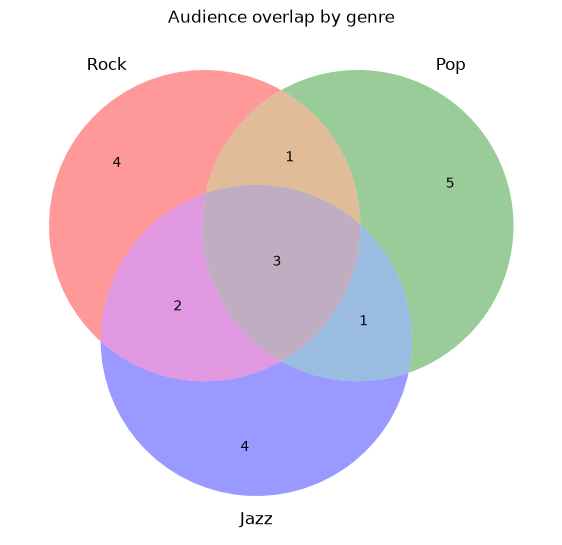

In [14]:
plt.figure(figsize=(7, 7))
venn3((rock_fans, pop_fans, jazz_fans), set_labels=('Rock', 'Pop', 'Jazz'))
plt.title('Audience overlap by genre')
plt.show()

## Task 2. Access configurator (RBAC)

### Access rules

In [47]:
def check_access(
  is_employee: bool,
  is_verified: bool,
  is_premium: bool,
  is_admin: bool,
  is_banned: bool,
) -> dict[str, bool]:
  return {
    'Base': is_employee and is_verified and not is_banned,
    'Premium': (is_employee or is_premium) and is_verified and not is_banned,
    'Admin': is_admin and is_verified and not is_banned,
    'Secret': (is_admin or (is_employee and is_premium)) and is_verified and not is_banned,
  }

### Truth table

In [52]:
PARAMS = ['is_employee', 'is_verified', 'is_premium', 'is_admin', 'is_banned']
PARAM_LABELS = ['Emp', 'Ver', 'Prem', 'Adm', 'Ban']
LEVELS = ['Base', 'Premium', 'Admin', 'Secret']
LEVEL_LABELS = ['Base', 'Prem', 'Adm', 'Secr']

truth_table = [
  (combination, check_access(*combination))
  for combination in itertools.product([True, False], repeat=5)
]

print(''.join(f'{label:<6}' for label in PARAM_LABELS) + '| ' + ''.join(f'{label:<6}' for label in LEVEL_LABELS))
print('-' * 65)
for combination, access in truth_table:
  inputs = ''.join(f'{int(value):<6}' for value in combination)
  outputs = ''.join(f'{int(access[level]):<6}' for level in LEVELS)
  print(f'{inputs}| {outputs}')

print(f'\nTotal rows: {len(truth_table)}')

Emp   Ver   Prem  Adm   Ban   | Base  Prem  Adm   Secr  
-----------------------------------------------------------------
1     1     1     1     1     | 0     0     0     0     
1     1     1     1     0     | 1     1     1     1     
1     1     1     0     1     | 0     0     0     0     
1     1     1     0     0     | 1     1     0     1     
1     1     0     1     1     | 0     0     0     0     
1     1     0     1     0     | 1     1     1     1     
1     1     0     0     1     | 0     0     0     0     
1     1     0     0     0     | 1     1     0     0     
1     0     1     1     1     | 0     0     0     0     
1     0     1     1     0     | 0     0     0     0     
1     0     1     0     1     | 0     0     0     0     
1     0     1     0     0     | 0     0     0     0     
1     0     0     1     1     | 0     0     0     0     
1     0     0     1     0     | 0     0     0     0     
1     0     0     0     1     | 0     0     0     0     
1     0     0     0   

### Analysis

In [74]:
full_access = [combination for combination, access in truth_table if all(access.values())]

print(f'Full access (all 4 sections): {len(full_access)} cases')
for combination in full_access:
  print(dict(zip(PARAMS, combination)))

Full access (all 4 sections): 2 cases
{'is_employee': True, 'is_verified': True, 'is_premium': True, 'is_admin': True, 'is_banned': False}
{'is_employee': True, 'is_verified': True, 'is_premium': False, 'is_admin': True, 'is_banned': False}


In [75]:
premium_without_base = [
  combination for combination, access in truth_table
  if access['Premium'] and not access['Base']
]

print(f'Premium without Base: {len(premium_without_base)} cases')
for combination in premium_without_base:
  print(dict(zip(PARAMS, combination)))

Premium without Base: 2 cases
{'is_employee': False, 'is_verified': True, 'is_premium': True, 'is_admin': True, 'is_banned': False}
{'is_employee': False, 'is_verified': True, 'is_premium': True, 'is_admin': False, 'is_banned': False}


### Conclusion

- Full access is granted in 2 of 32 cases: an employee who is an admin, verified and not banned; `is_premium` does not matter.
- Premium without Base exists in 2 cases: a verified, not banned non-employee with a premium subscription (`is_admin` does not matter).
- It happens because Premium requires `is_employee or is_premium`, while Base requires `is_employee` only, so a paying external user gets Premium content but not the employee Base section.

## Task 3. Dream team

In [77]:
BACKEND_CANDIDATES, BACKEND_NEEDED = 8, 2
FRONTEND_CANDIDATES, FRONTEND_NEEDED = 6, 2
DESIGNER_CANDIDATES, DESIGNERS_NEEDED = 4, 1

### Back-end

In [78]:
backend_ways = math.comb(BACKEND_CANDIDATES, BACKEND_NEEDED)

print(f'Back-end: C({BACKEND_CANDIDATES}, {BACKEND_NEEDED}) = {backend_ways} ways')

Back-end: C(8, 2) = 28 ways


### Front-end

In [79]:
frontend_ways = math.comb(FRONTEND_CANDIDATES, FRONTEND_NEEDED)

print(f'Front-end: C({FRONTEND_CANDIDATES}, {FRONTEND_NEEDED}) = {frontend_ways} ways')

Front-end: C(6, 2) = 15 ways


### Designer

In [81]:
designer_ways = math.comb(DESIGNER_CANDIDATES, DESIGNERS_NEEDED)

print(f'Designer: C({DESIGNER_CANDIDATES}, {DESIGNERS_NEEDED}) = {designer_ways} ways')

Designer: C(4, 1) = 4 ways


### Total

In [82]:
total_teams = backend_ways * frontend_ways * designer_ways

print(f'Total unique teams: {backend_ways} × {frontend_ways} × {designer_ways} = {total_teams}')

Total unique teams: 28 × 15 × 4 = 1680


## Task 4. Company social graph

### Adjacency list

In [84]:
adjacency_list = {
  'Anna': ['Bohdan', 'Viktor', 'Hanna'],
  'Bohdan': ['Anna', 'Viktor', 'Dmytro'],
  'Viktor': ['Anna', 'Bohdan', 'Hanna', 'Dmytro'],
  'Hanna': ['Anna', 'Viktor', 'Yevhen'],
  'Dmytro': ['Bohdan', 'Viktor', 'Yevhen'],
  'Yevhen': ['Hanna', 'Dmytro'],
}

is_undirected = all(
  person in adjacency_list[neighbor]
  for person, neighbors in adjacency_list.items()
  for neighbor in neighbors
)

for person, neighbors in adjacency_list.items():
  print(f'{person}: {neighbors}')
print(f'\nUndirected (every link is mutual): {is_undirected}')

Anna: ['Bohdan', 'Viktor', 'Hanna']
Bohdan: ['Anna', 'Viktor', 'Dmytro']
Viktor: ['Anna', 'Bohdan', 'Hanna', 'Dmytro']
Hanna: ['Anna', 'Viktor', 'Yevhen']
Dmytro: ['Bohdan', 'Viktor', 'Yevhen']
Yevhen: ['Hanna', 'Dmytro']

Undirected (every link is mutual): True


### Adjacency matrix

In [86]:
employees = list(adjacency_list)
index = {name: i for i, name in enumerate(employees)}

adjacency_matrix = [[0] * len(employees) for _ in employees]
for person, neighbors in adjacency_list.items():
  for neighbor in neighbors:
    adjacency_matrix[index[person]][index[neighbor]] = 1

is_symmetric = all(
  adjacency_matrix[i][j] == adjacency_matrix[j][i]
  for i in range(len(employees))
  for j in range(len(employees))
)

print(' ' * 8 + ''.join(f'{name:<8}' for name in employees))
for name, row in zip(employees, adjacency_matrix):
  print(f'{name:<8}' + ''.join(f'{value:<8}' for value in row))
print(f'\nSymmetric: {is_symmetric}')

        Anna    Bohdan  Viktor  Hanna   Dmytro  Yevhen  
Anna    0       1       1       1       0       0       
Bohdan  1       0       1       0       1       0       
Viktor  1       1       0       1       1       0       
Hanna   1       0       1       0       0       1       
Dmytro  0       1       1       0       0       1       
Yevhen  0       0       0       1       1       0       

Symmetric: True


### Edge list

In [91]:
edges = [
  (employees[i], employees[j])
  for i in range(len(employees))
  for j in range(i + 1, len(employees))
  if adjacency_matrix[i][j] == 1
]

for edge in edges:
  print(edge)
print(f'\nUnique edges: {len(edges)}')

('Anna', 'Bohdan')
('Anna', 'Viktor')
('Anna', 'Hanna')
('Bohdan', 'Viktor')
('Bohdan', 'Dmytro')
('Viktor', 'Hanna')
('Viktor', 'Dmytro')
('Hanna', 'Yevhen')
('Dmytro', 'Yevhen')

Unique edges: 9


### Vertex degrees

In [92]:
degrees = {person: len(neighbors) for person, neighbors in adjacency_list.items()}
max_degree = max(degrees.values())
min_degree = min(degrees.values())

for person, degree in degrees.items():
  print(f'{person}: {degree}')

most_social = [person for person, degree in degrees.items() if degree == max_degree]
least_social = [person for person, degree in degrees.items() if degree == min_degree]

print(f'\nMost communicative: {most_social} ({max_degree} contacts)')
print(f'Least communicative: {least_social} ({min_degree} contacts)')

Anna: 3
Bohdan: 3
Viktor: 4
Hanna: 3
Dmytro: 3
Yevhen: 2

Most communicative: ['Viktor'] (4 contacts)
Least communicative: ['Yevhen'] (2 contacts)


### Handshake lemma

In [93]:
degree_sum = sum(degrees.values())

print(f'Sum of degrees: {degree_sum}')
print(f'Number of edges: {len(edges)}')
print(f'{degree_sum} == 2 × {len(edges)}: {degree_sum == 2 * len(edges)}')

Sum of degrees: 18
Number of edges: 9
18 == 2 × 9: True


## Conclusion

- 20 unique users listened to at least one genre; users 105, 110 and 115 listened to all three.
- Pure rock fans (rock only) are 101, 107, 109 and 118 — the audience for niche rock ads.
- 4 users listened to exactly two genres: 102, 103, 108 and 112.
- Full access happens in 2 of 32 parameter combinations; Premium without Base is possible for a premium non-employee.
- A team of 2 back-end, 2 front-end and 1 designer can be formed in 28 × 15 × 4 = 1680 ways.
- Viktor is the most communicative employee (4 contacts), Yevhen the least (2); the sum of degrees 18 equals 2 × 9 edges.